### Exercício 1

In [3]:
def calculo_FFT(dados, freqAmostra):
    qtd_amostras = len(dados)
    yf = np.abs(np.fft.rfft(dados)) / qtd_amostras
    xf = np.fft.rfftfreq(qtd_amostras, d=1/freqAmostra)
    return xf, yf

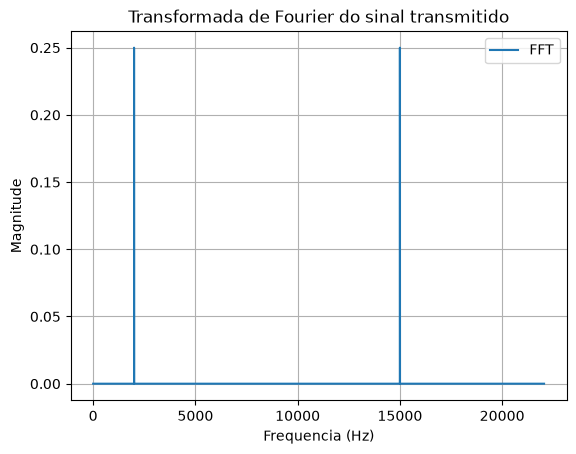

In [4]:
import numpy as np
import matplotlib.pyplot as plt

fs = 44100
tempo = np.linspace(0, 2, fs*2, endpoint=False)

senoide = np.sin(2*np.pi* 2*(1e3) *tempo)
portadora = np.sin(2*np.pi* 15*(1e3) *tempo)

resultante = (senoide+portadora)/2

xf, yf = calculo_FFT(resultante, fs)

plt.figure()
plt.plot(xf, yf, label="FFT")
plt.xlabel("Frequencia (Hz)")
plt.ylabel("Magnitude")
plt.title("Transformada de Fourier do sinal transmitido")
plt.grid()
plt.legend()
plt.show()


### Exercício 2
A banda mínima seria 13kHz e a máxima seria 17kHz.

### Exercício 3

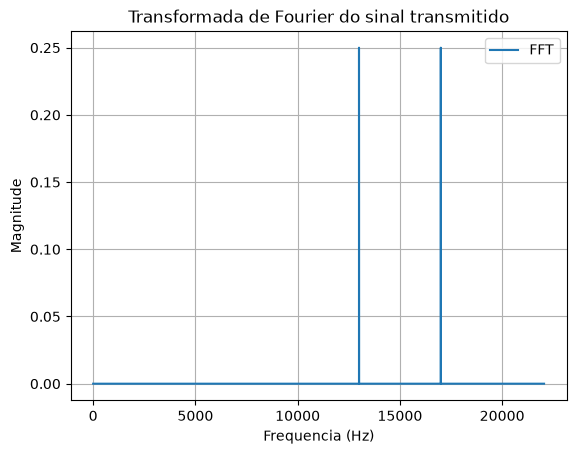

In [5]:
fs = 44100
tempo = np.linspace(0, 2, fs*2, endpoint=False)

m_t = np.sin(2*np.pi* 2*(1e3) *tempo)
c_t = np.sin(2*np.pi* 15*(1e3) *tempo)

s_t = m_t*c_t
d_t = s_t*c_t
xf, yf = calculo_FFT(s_t, fs)

plt.figure()
plt.plot(xf, yf, label="FFT")
plt.xlabel("Frequencia (Hz)")
plt.ylabel("Magnitude")
plt.title("Transformada de Fourier do sinal transmitido")
plt.grid()
plt.legend()
plt.show()

### Exercício 4
Considerando uma portadora de 15kHz, só tem 1kHz de informação a ser mandado, 15-14=1 e 16-15=1. Dessa forma, o sinal m(t), que contém informação, deverá passar por um filtro paixa-baixa, ainda que informação seja perdida.

### Exercício 5

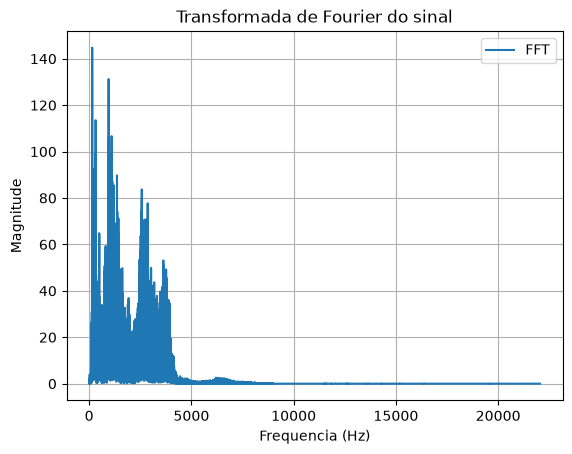

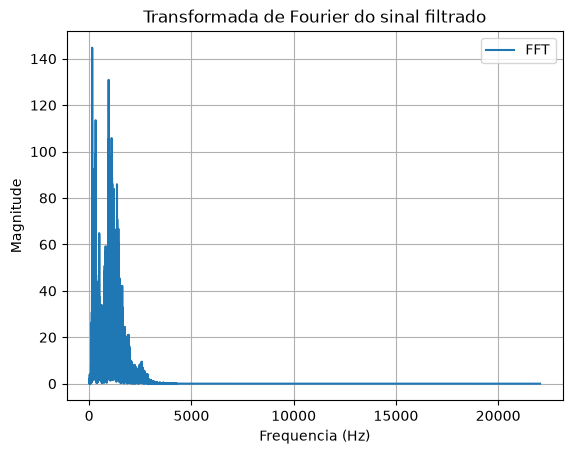

Tocando áudio filtrado:
Áudio filtrado tocado.
Tocando áudio modulado:
Áudio modulado tocado.


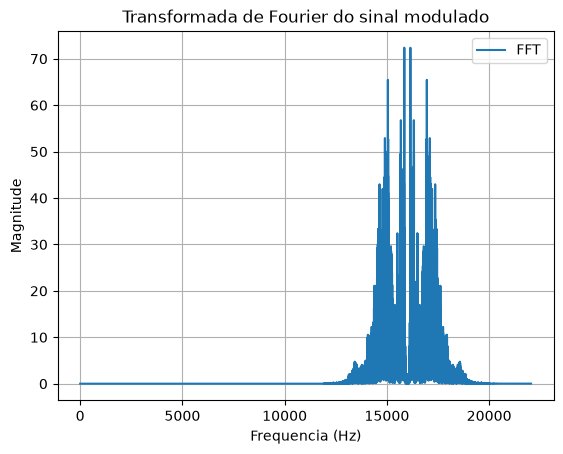

Tocando áudio demodulado:
Áudio demodulado tocado.


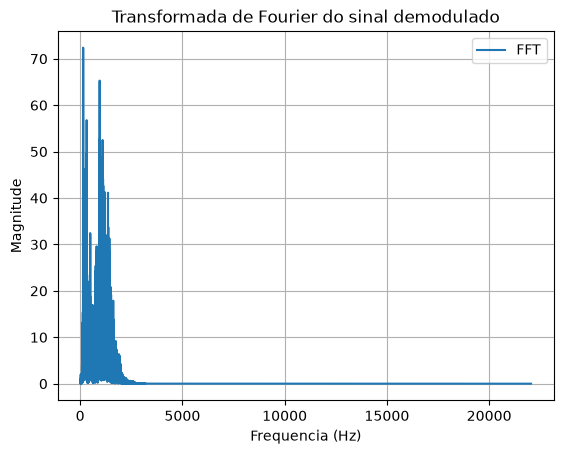

In [18]:
from scipy.io import wavfile
from scipy import signal
import sounddevice as sd

def passa_baixa(sinal, fc, fs, ordem=4):
    nyq = fs / 2
    b, a = signal.butter(ordem, fc / nyq, btype='low')
    return signal.filtfilt(b, a, sinal)

duracao = 5

fs, dados = wavfile.read('gravacao.wav')
dados = dados[:duracao*fs]

xf, yf = calculo_FFT(dados, fs)

plt.figure()
plt.plot(xf, yf, label="FFT")
plt.xlabel("Frequencia (Hz)")
plt.ylabel("Magnitude")
plt.title("Transformada de Fourier do sinal")
plt.grid()
plt.legend()
plt.show()

dados_filtrados = passa_baixa(dados, 2e3, fs)
xff, yff = calculo_FFT(dados_filtrados, fs)

plt.figure()
plt.plot(xff, yff, label="FFT")
plt.xlabel("Frequencia (Hz)")
plt.ylabel("Magnitude")
plt.title("Transformada de Fourier do sinal filtrado")
plt.grid()
plt.legend()
plt.show()

print("Tocando áudio filtrado:")
sd.play(dados_filtrados, fs)
sd.wait()
print("Áudio filtrado tocado.")

tempo = np.linspace(0, 5, fs*5, endpoint=False)
portadora = np.sin(2*np.pi* 16*(1e3) *tempo)

dados_modulados = dados_filtrados*portadora

xf_m, yf_m = calculo_FFT(dados_modulados, fs)

print("Tocando áudio modulado:")
sd.play(dados_modulados, fs)
sd.wait()
print("Áudio modulado tocado.")

plt.figure()
plt.plot(xf_m, yf_m, label="FFT")
plt.xlabel("Frequencia (Hz)")
plt.ylabel("Magnitude")
plt.title("Transformada de Fourier do sinal modulado")
plt.grid()
plt.legend()
plt.show()

dados_demodulados = dados_modulados*portadora

dados_demodulados_filtrados = passa_baixa(dados_demodulados, 2e3, fs)

xf_d, yf_d = calculo_FFT(dados_demodulados_filtrados, fs)

print("Tocando áudio demodulado:")
sd.play(dados_demodulados_filtrados, fs)
sd.wait()
print("Áudio demodulado tocado.")

plt.figure()
plt.plot(xf_d, yf_d, label="FFT")
plt.xlabel("Frequencia (Hz)")
plt.ylabel("Magnitude")
plt.title("Transformada de Fourier do sinal demodulado")
plt.grid()
plt.legend()
plt.show()
